In [3]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch.utils.data import DataLoader, Subset, Dataset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [4]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [5]:
from pathlib import Path
import os

DATA_DIR = Path("/content/gdrive/MyDrive/mth416/data")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test" / "test samples"

print("\nTrain folders:", os.listdir(TRAIN_DIR))
print("Val folders:", os.listdir(VAL_DIR))

if (DATA_DIR / "test").exists():
    print("Test folders:", os.listdir(DATA_DIR / "test"))

if TEST_DIR.exists():
    print("Number of test images:", len(list(TEST_DIR.glob("*.jpeg"))))


Train folders: ['abnormal', 'normal']
Val folders: ['normal', 'abnormal']
Test folders: ['test samples']
Number of test images: 100


In [6]:
IMG_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp"]

def count_images(folder):
    folder = Path(folder)
    count = 0
    for ext in IMG_EXTENSIONS:
        count += len(list(folder.glob(f"*{ext}")))
    return count

for split_name, split_dir in [("train", TRAIN_DIR), ("val", VAL_DIR)]:
    print(f"\n{split_name.upper()}")
    for cls in ["abnormal", "normal"]:
        cls_dir = split_dir / cls
        print(cls, ":", count_images(cls_dir))

print("\nTEST")
print("test samples:", count_images(TEST_DIR))


TRAIN
abnormal : 3165
normal : 1092

VAL
abnormal : 734
normal : 257

TEST
test samples: 100


In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path
import torch
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=val_test_transform)

print("Classes:", train_dataset.classes)
print("Class to index:", train_dataset.class_to_idx)
print("Number of training images:", len(train_dataset))
print("Number of validation images:", len(val_dataset))

Classes: ['abnormal', 'normal']
Class to index: {'abnormal': 0, 'normal': 1}
Number of training images: 4257
Number of validation images: 991


Number of normal images: 1092
Number of abnormal images: 3165


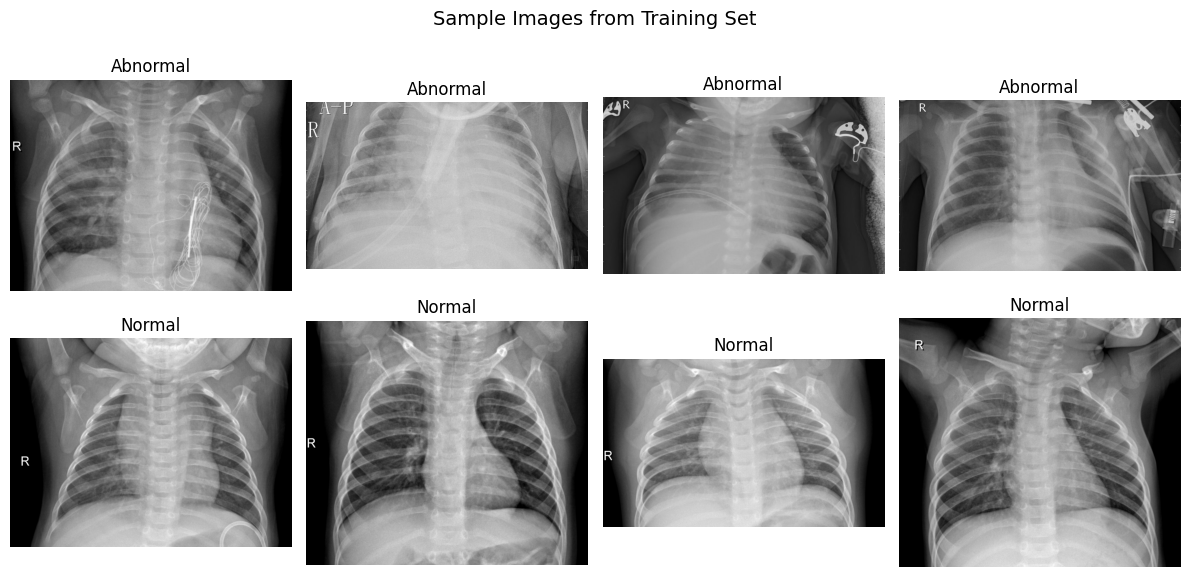

Saved sample image figure to: /content/gdrive/MyDrive/mth416/figures/sample_images.png


In [8]:
# Save figures for the report
FIGURE_DIR = Path("/content/gdrive/MyDrive/mth416/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def get_image_paths(folder):
    folder = Path(folder)
    paths = []
    for ext in [".jpg", ".jpeg", ".png", ".bmp"]:
        paths.extend(list(folder.glob(f"*{ext}")))
    return paths

normal_paths = get_image_paths(TRAIN_DIR / "normal")
abnormal_paths = get_image_paths(TRAIN_DIR / "abnormal")

print("Number of normal images:", len(normal_paths))
print("Number of abnormal images:", len(abnormal_paths))

random.seed(42)

sample_normal = random.sample(normal_paths, 4)
sample_abnormal = random.sample(abnormal_paths, 4)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, path in enumerate(sample_abnormal):
    img = Image.open(path).convert("RGB")
    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title("Abnormal")
    axes[0, i].axis("off")

for i, path in enumerate(sample_normal):
    img = Image.open(path).convert("RGB")
    axes[1, i].imshow(img, cmap="gray")
    axes[1, i].set_title("Normal")
    axes[1, i].axis("off")

plt.suptitle("Sample Images from Training Set", fontsize=14)
plt.tight_layout()

sample_image_path = FIGURE_DIR / "sample_images.png"
plt.savefig(sample_image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved sample image figure to:", sample_image_path)

In [9]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Example labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Example labels: tensor([1, 0, 0, 1, 1, 0, 0, 0, 0, 0])


In [10]:
# Training evaluation loader without random augmentation
train_eval_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=val_test_transform
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Number of training evaluation images:", len(train_eval_dataset))

Number of training evaluation images: 4257


In [11]:
targets = np.array(train_dataset.targets)

class_counts = np.bincount(targets)
num_classes = len(class_counts)

class_weights = len(targets) / (num_classes * class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)
print("Class mapping:", train_dataset.class_to_idx)

Class counts: [3165 1092]
Class weights: tensor([0.6725, 1.9492], device='cuda:0')
Class mapping: {'abnormal': 0, 'normal': 1}


In [13]:
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(SimpleCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 14 * 14, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model_q1 = SimpleCNN(num_classes=2).to(device)

print(model_q1)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, af

In [14]:
def count_parameters(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total_params, trainable_params

total_params, trainable_params = count_parameters(model_q1)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 26,081,026
Trainable parameters: 26,081,026


In [15]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model_q1.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [16]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            running_loss += loss.item() * images.size(0)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc, np.array(all_labels), np.array(all_preds), np.array(all_probs)

In [18]:
EPOCHS = 10

history_q1 = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0
best_model_path_q1 = str(DATA_DIR / "best_q1.pth")
print(best_model_path_q1)

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model_q1, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc, val_labels, val_preds, val_probs = evaluate(
        model_q1, val_loader, criterion, device
    )

    scheduler.step(val_acc)

    history_q1["train_loss"].append(train_loss)
    history_q1["train_acc"].append(train_acc)
    history_q1["val_loss"].append(val_loss)
    history_q1["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model_q1.state_dict(), best_model_path_q1)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

print("Best validation accuracy:", best_val_acc)
print("Best model saved to:", best_model_path_q1)

/content/gdrive/MyDrive/mth416/data/best_q1.pth
Epoch [1/10] Train Loss: 0.3332 | Train Acc: 0.8858 Val Loss: 0.1047 | Val Acc: 0.9647
Epoch [2/10] Train Loss: 0.1454 | Train Acc: 0.9467 Val Loss: 0.0816 | Val Acc: 0.9717
Epoch [3/10] Train Loss: 0.1711 | Train Acc: 0.9352 Val Loss: 0.1151 | Val Acc: 0.9536
Epoch [4/10] Train Loss: 0.1151 | Train Acc: 0.9535 Val Loss: 0.0742 | Val Acc: 0.9748
Epoch [5/10] Train Loss: 0.1107 | Train Acc: 0.9601 Val Loss: 0.1721 | Val Acc: 0.9374
Epoch [6/10] Train Loss: 0.0932 | Train Acc: 0.9655 Val Loss: 0.1003 | Val Acc: 0.9606
Epoch [7/10] Train Loss: 0.0945 | Train Acc: 0.9641 Val Loss: 0.0563 | Val Acc: 0.9778
Epoch [8/10] Train Loss: 0.0942 | Train Acc: 0.9652 Val Loss: 0.0626 | Val Acc: 0.9778
Epoch [9/10] Train Loss: 0.1477 | Train Acc: 0.9467 Val Loss: 0.0589 | Val Acc: 0.9778
Epoch [10/10] Train Loss: 0.0828 | Train Acc: 0.9683 Val Loss: 0.0677 | Val Acc: 0.9728
Best validation accuracy: 0.9778002018163471
Best model saved to: /content/gdrive

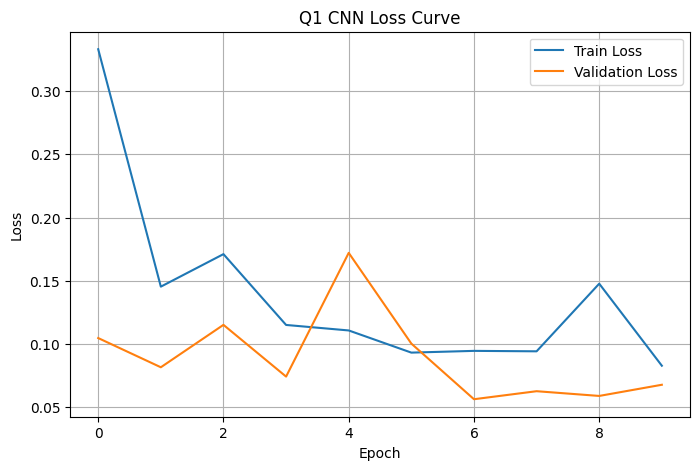

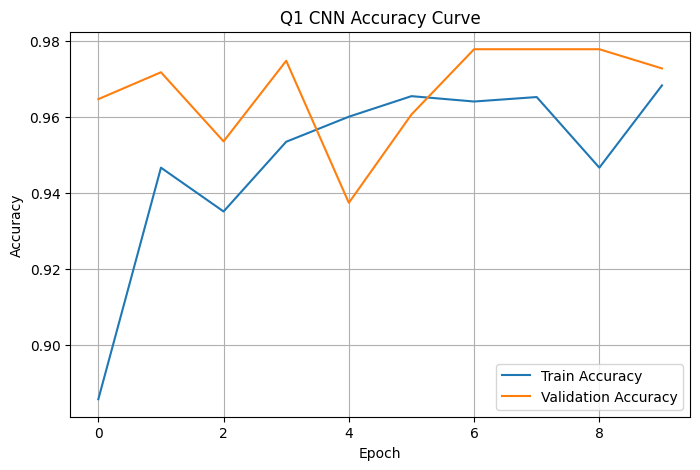

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history_q1["train_loss"], label="Train Loss")
plt.plot(history_q1["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Q1 CNN Loss Curve")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_q1["train_acc"], label="Train Accuracy")
plt.plot(history_q1["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Q1 CNN Accuracy Curve")
plt.legend()
plt.grid(True)
plt.show()

Validation accuracy: 0.9778002018163471

Classification report:
              precision    recall  f1-score   support

    abnormal       0.98      0.99      0.99       734
      normal       0.96      0.95      0.96       257

    accuracy                           0.98       991
   macro avg       0.97      0.97      0.97       991
weighted avg       0.98      0.98      0.98       991



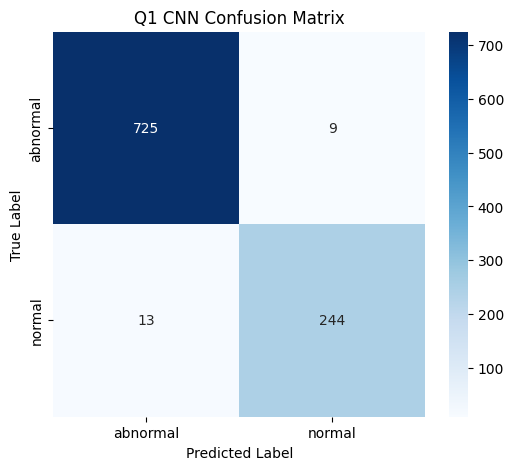

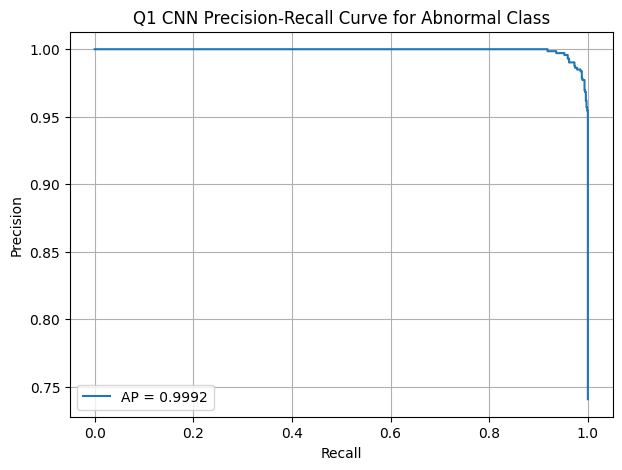

Average Precision for abnormal class: 0.9991724250427725


In [20]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import precision_recall_curve, average_precision_score
import seaborn as sns

# Load best model
model_q1.load_state_dict(torch.load(best_model_path_q1, map_location=device))

val_loss, val_acc, val_labels, val_preds, val_probs = evaluate(
    model_q1, val_loader, criterion, device
)

print("Validation accuracy:", val_acc)
print("\nClassification report:")
print(classification_report(
    val_labels,
    val_preds,
    target_names=train_dataset.classes
))

cm = confusion_matrix(val_labels, val_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Q1 CNN Confusion Matrix")
plt.show()

# abnormal is positive class
abnormal_idx = train_dataset.class_to_idx["abnormal"]
abnormal_scores = val_probs[:, abnormal_idx]

precision, recall, thresholds = precision_recall_curve(
    val_labels,
    abnormal_scores,
    pos_label=abnormal_idx
)

ap_score = average_precision_score(
    (val_labels == abnormal_idx).astype(int),
    abnormal_scores
)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"AP = {ap_score:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Q1 CNN Precision-Recall Curve for Abnormal Class")
plt.legend()
plt.grid(True)
plt.show()

print("Average Precision for abnormal class:", ap_score)

Q1 Training accuracy: 0.979328165374677

Q1 Training classification report:
              precision    recall  f1-score   support

    abnormal       0.99      0.98      0.99      3165
      normal       0.95      0.97      0.96      1092

    accuracy                           0.98      4257
   macro avg       0.97      0.98      0.97      4257
weighted avg       0.98      0.98      0.98      4257



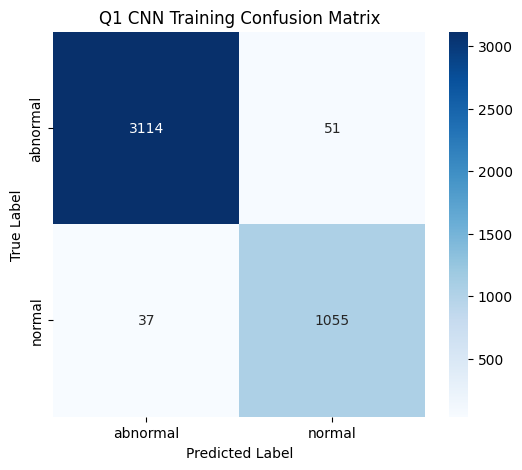

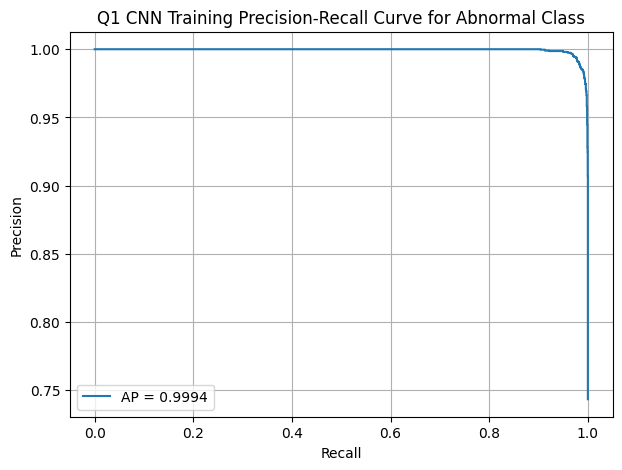

Q1 Training AP for abnormal class: 0.9993919907233639


In [21]:
# Q1 Training set evaluation
model_q1.load_state_dict(torch.load(best_model_path_q1, map_location=device))

train_loss_q1, train_acc_q1, train_labels_q1, train_preds_q1, train_probs_q1 = evaluate(
    model_q1, train_eval_loader, criterion, device
)

print("Q1 Training accuracy:", train_acc_q1)
print("\nQ1 Training classification report:")
print(classification_report(
    train_labels_q1,
    train_preds_q1,
    target_names=train_eval_dataset.classes
))

cm_train_q1 = confusion_matrix(train_labels_q1, train_preds_q1)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_train_q1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_eval_dataset.classes,
    yticklabels=train_eval_dataset.classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Q1 CNN Training Confusion Matrix")
plt.show()

abnormal_idx = train_eval_dataset.class_to_idx["abnormal"]
abnormal_scores_train_q1 = train_probs_q1[:, abnormal_idx]

precision_train_q1, recall_train_q1, _ = precision_recall_curve(
    train_labels_q1,
    abnormal_scores_train_q1,
    pos_label=abnormal_idx
)

ap_train_q1 = average_precision_score(
    (train_labels_q1 == abnormal_idx).astype(int),
    abnormal_scores_train_q1
)

plt.figure(figsize=(7, 5))
plt.plot(recall_train_q1, precision_train_q1, label=f"AP = {ap_train_q1:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Q1 CNN Training Precision-Recall Curve for Abnormal Class")
plt.legend()
plt.grid(True)
plt.show()

print("Q1 Training AP for abnormal class:", ap_train_q1)

In [ ]:
#Q2
import torch
import torch.nn as nn
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT
model_q2 = models.resnet18(weights=weights)

print(model_q2)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 234MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
# Freeze all layers first
for param in model_q2.parameters():
    param.requires_grad = False

# Unfreeze layer4 for fine-tuning
for param in model_q2.layer4.parameters():
    param.requires_grad = True

# Replace the final fully connected layer
num_features = model_q2.fc.in_features
model_q2.fc = nn.Linear(num_features, 2)

# The new fc layer is trainable by default
model_q2 = model_q2.to(device)

print(model_q2.fc)

Linear(in_features=512, out_features=2, bias=True)


In [ ]:
total_params_q2 = sum(p.numel() for p in model_q2.parameters())
trainable_params_q2 = sum(p.numel() for p in model_q2.parameters() if p.requires_grad)

print(f"Q2 Total parameters: {total_params_q2:,}")
print(f"Q2 Fine-tuning / trainable parameters: {trainable_params_q2:,}")

Q2 Total parameters: 11,177,538
Q2 Fine-tuning / trainable parameters: 8,394,754


In [ ]:
criterion_q2 = nn.CrossEntropyLoss(weight=class_weights)

optimizer_q2 = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_q2.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler_q2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_q2,
    mode="max",
    factor=0.5,
    patience=2
)

In [ ]:
EPOCHS_Q2 = 10

history_q2 = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc_q2 = 0.0
best_model_path_q2 = str(DATA_DIR / "best_q2_resnet18.pth")
print(best_model_path_q2)

for epoch in range(EPOCHS_Q2):
    train_loss, train_acc = train_one_epoch(
        model_q2, train_loader, criterion_q2, optimizer_q2, device
    )

    val_loss, val_acc, val_labels_q2, val_preds_q2, val_probs_q2 = evaluate(
        model_q2, val_loader, criterion_q2, device
    )

    scheduler_q2.step(val_acc)

    history_q2["train_loss"].append(train_loss)
    history_q2["train_acc"].append(train_acc)
    history_q2["val_loss"].append(val_loss)
    history_q2["val_acc"].append(val_acc)

    if val_acc > best_val_acc_q2:
        best_val_acc_q2 = val_acc
        torch.save(model_q2.state_dict(), best_model_path_q2)

    print(
        f"Epoch [{epoch+1}/{EPOCHS_Q2}] "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

print("Best Q2 validation accuracy:", best_val_acc_q2)
print("Best Q2 model saved to:", best_model_path_q2)

/content/gdrive/MyDrive/mth416/data/best_q2_resnet18.pth
Epoch [1/10] Train Loss: 0.1296 | Train Acc: 0.9500 Val Loss: 0.1349 | Val Acc: 0.9516
Epoch [2/10] Train Loss: 0.0832 | Train Acc: 0.9730 Val Loss: 0.0703 | Val Acc: 0.9717
Epoch [3/10] Train Loss: 0.0550 | Train Acc: 0.9789 Val Loss: 0.0756 | Val Acc: 0.9728
Epoch [4/10] Train Loss: 0.0390 | Train Acc: 0.9859 Val Loss: 0.0554 | Val Acc: 0.9818
Epoch [5/10] Train Loss: 0.0385 | Train Acc: 0.9854 Val Loss: 0.0675 | Val Acc: 0.9717
Epoch [6/10] Train Loss: 0.0354 | Train Acc: 0.9864 Val Loss: 0.0420 | Val Acc: 0.9788
Epoch [7/10] Train Loss: 0.0316 | Train Acc: 0.9868 Val Loss: 0.0714 | Val Acc: 0.9717
Epoch [8/10] Train Loss: 0.0246 | Train Acc: 0.9908 Val Loss: 0.0436 | Val Acc: 0.9828
Epoch [9/10] Train Loss: 0.0199 | Train Acc: 0.9930 Val Loss: 0.0322 | Val Acc: 0.9879
Epoch [10/10] Train Loss: 0.0150 | Train Acc: 0.9951 Val Loss: 0.0443 | Val Acc: 0.9788
Best Q2 validation accuracy: 0.987891019172553
Best Q2 model saved to: /

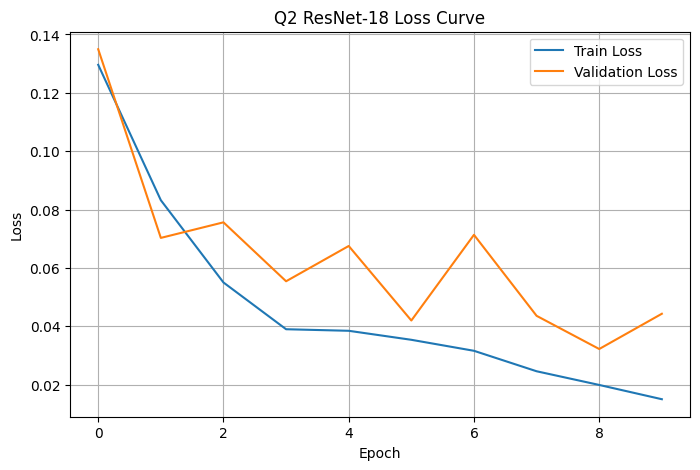

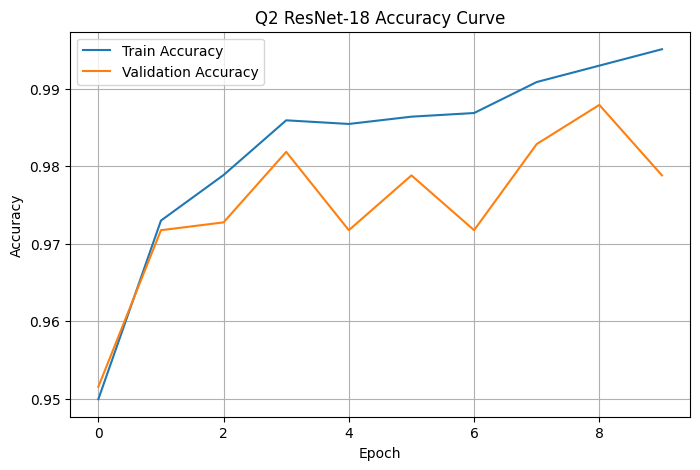

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history_q2["train_loss"], label="Train Loss")
plt.plot(history_q2["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Q2 ResNet-18 Loss Curve")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_q2["train_acc"], label="Train Accuracy")
plt.plot(history_q2["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Q2 ResNet-18 Accuracy Curve")
plt.legend()
plt.grid(True)
plt.show()

Q2 Validation accuracy: 0.987891019172553

Q2 Classification report:
              precision    recall  f1-score   support

    abnormal       0.99      0.99      0.99       734
      normal       0.98      0.97      0.98       257

    accuracy                           0.99       991
   macro avg       0.99      0.98      0.98       991
weighted avg       0.99      0.99      0.99       991



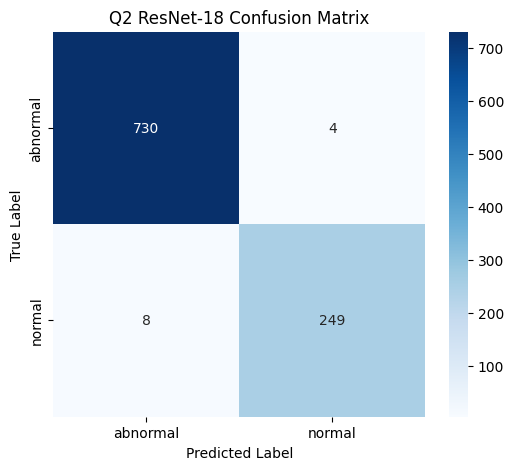

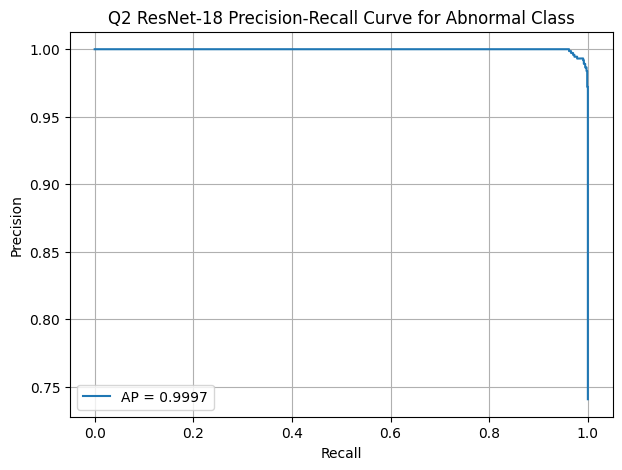

Q2 Average Precision for abnormal class: 0.999719611759277


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import precision_recall_curve, average_precision_score
import seaborn as sns

model_q2.load_state_dict(torch.load(best_model_path_q2, map_location=device))

val_loss_q2, val_acc_q2, val_labels_q2, val_preds_q2, val_probs_q2 = evaluate(
    model_q2, val_loader, criterion_q2, device
)

print("Q2 Validation accuracy:", val_acc_q2)

print("\nQ2 Classification report:")
print(classification_report(
    val_labels_q2,
    val_preds_q2,
    target_names=train_dataset.classes
))

cm_q2 = confusion_matrix(val_labels_q2, val_preds_q2)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_q2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Q2 ResNet-18 Confusion Matrix")
plt.show()

abnormal_idx = train_dataset.class_to_idx["abnormal"]
abnormal_scores_q2 = val_probs_q2[:, abnormal_idx]

precision_q2, recall_q2, thresholds_q2 = precision_recall_curve(
    val_labels_q2,
    abnormal_scores_q2,
    pos_label=abnormal_idx
)

ap_score_q2 = average_precision_score(
    (val_labels_q2 == abnormal_idx).astype(int),
    abnormal_scores_q2
)

plt.figure(figsize=(7, 5))
plt.plot(recall_q2, precision_q2, label=f"AP = {ap_score_q2:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Q2 ResNet-18 Precision-Recall Curve for Abnormal Class")
plt.legend()
plt.grid(True)
plt.show()

print("Q2 Average Precision for abnormal class:", ap_score_q2)

In [ ]:
# Q2 Training set evaluation
model_q2.load_state_dict(torch.load(best_model_path_q2, map_location=device))

train_loss_q2, train_acc_q2, train_labels_q2, train_preds_q2, train_probs_q2 = evaluate(
    model_q2, train_eval_loader, criterion_q2, device
)

print("Q2 Training accuracy:", train_acc_q2)
print("\nQ2 Training classification report:")
print(classification_report(
    train_labels_q2,
    train_preds_q2,
    target_names=train_eval_dataset.classes
))

cm_train_q2 = confusion_matrix(train_labels_q2, train_preds_q2)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_train_q2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_eval_dataset.classes,
    yticklabels=train_eval_dataset.classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Q2 ResNet-18 Training Confusion Matrix")
plt.show()

abnormal_idx = train_eval_dataset.class_to_idx["abnormal"]
abnormal_scores_train_q2 = train_probs_q2[:, abnormal_idx]

precision_train_q2, recall_train_q2, _ = precision_recall_curve(
    train_labels_q2,
    abnormal_scores_train_q2,
    pos_label=abnormal_idx
)

ap_train_q2 = average_precision_score(
    (train_labels_q2 == abnormal_idx).astype(int),
    abnormal_scores_train_q2
)

plt.figure(figsize=(7, 5))
plt.plot(recall_train_q2, precision_train_q2, label=f"AP = {ap_train_q2:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Q2 ResNet-18 Training Precision-Recall Curve for Abnormal Class")
plt.legend()
plt.grid(True)
plt.show()

print("Q2 Training AP for abnormal class:", ap_train_q2)

In [ ]:
#Q3
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

DATA_DIR = Path("/content/gdrive/MyDrive/mth416/data")

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test" / "test samples"

MODEL_PATH = DATA_DIR / "best_q2_resnet18.pth"

print("Train dir exists:", TRAIN_DIR.exists())
print("Test dir exists:", TEST_DIR.exists())
print("Model exists:", MODEL_PATH.exists())
print("Model path:", MODEL_PATH)

Using device: cuda
Train dir exists: True
Test dir exists: True
Model exists: True
Model path: /content/gdrive/MyDrive/mth416/data/best_q2_resnet18.pth


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=val_test_transform)

print("Classes:", train_dataset.classes)
print("Class to index:", train_dataset.class_to_idx)

idx_to_class = {v: k for k, v in train_dataset.class_to_idx.items()}
print("Index to class:", idx_to_class)

Classes: ['abnormal', 'normal']
Class to index: {'abnormal': 0, 'normal': 1}
Index to class: {0: 'abnormal', 1: 'normal'}


In [ ]:
IMG_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp"]

class TestImageDataset(Dataset):
    def __init__(self, test_dir, transform=None):
        self.test_dir = Path(test_dir)
        self.transform = transform

        self.image_paths = []
        for ext in IMG_EXTENSIONS:
            self.image_paths.extend(list(self.test_dir.glob(f"*{ext}")))

        def sort_key(path):
            try:
                return int(path.stem)
            except:
                return path.name

        self.image_paths = sorted(self.image_paths, key=sort_key)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]
        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        image_id = path.name
        return image, image_id

In [ ]:
test_dataset = TestImageDataset(TEST_DIR, transform=val_test_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Number of test images:", len(test_dataset))

test_images, test_ids = next(iter(test_loader))
print("Test image batch shape:", test_images.shape)
print("First test ids:", test_ids[:10])

Number of test images: 100
Test image batch shape: torch.Size([32, 3, 224, 224])
First test ids: ('1.jpeg', '2.jpeg', '3.jpeg', '4.jpeg', '5.jpeg', '6.jpeg', '7.jpeg', '8.jpeg', '9.jpeg', '10.jpeg')


In [ ]:
weights = models.ResNet18_Weights.DEFAULT
model_q2 = models.resnet18(weights=weights)

num_features = model_q2.fc.in_features
model_q2.fc = nn.Linear(num_features, 2)

model_q2.load_state_dict(torch.load(MODEL_PATH, map_location=device))

model_q2 = model_q2.to(device)
model_q2.eval()

print("Best Q2 ResNet-18 model loaded successfully.")

Best Q2 ResNet-18 model loaded successfully.


In [ ]:
test_predictions = []

model_q2.eval()

with torch.no_grad():
    for images, image_ids in test_loader:
        images = images.to(device)

        outputs = model_q2(images)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        for image_id, pred_idx, prob in zip(
            image_ids,
            preds.cpu().numpy(),
            probs.cpu().numpy()
        ):
            predicted_label = idx_to_class[int(pred_idx)]
            confidence = float(np.max(prob))

            test_predictions.append({
                "id": image_id,
                "predicted_label": predicted_label,
                "confidence": confidence
            })

test_predictions_df = pd.DataFrame(test_predictions)

print(test_predictions_df.head(20))

print("\nPrediction counts:")
print(test_predictions_df["predicted_label"].value_counts())

         id predicted_label  confidence
0    1.jpeg        abnormal    0.999986
1    2.jpeg        abnormal    0.999949
2    3.jpeg        abnormal    0.999998
3    4.jpeg        abnormal    0.999761
4    5.jpeg        abnormal    0.999925
5    6.jpeg        abnormal    0.998373
6    7.jpeg        abnormal    0.998616
7    8.jpeg          normal    0.648408
8    9.jpeg        abnormal    0.999986
9   10.jpeg        abnormal    0.989771
10  11.jpeg          normal    0.989506
11  12.jpeg        abnormal    0.999870
12  13.jpeg        abnormal    0.998487
13  14.jpeg        abnormal    0.999980
14  15.jpeg        abnormal    1.000000
15  16.jpeg        abnormal    0.999955
16  17.jpeg        abnormal    0.999991
17  18.jpeg        abnormal    0.999957
18  19.jpeg        abnormal    0.999959
19  20.jpeg        abnormal    0.999751

Prediction counts:
predicted_label
abnormal    98
normal       2
Name: count, dtype: int64


['8.jpeg', '11.jpeg']


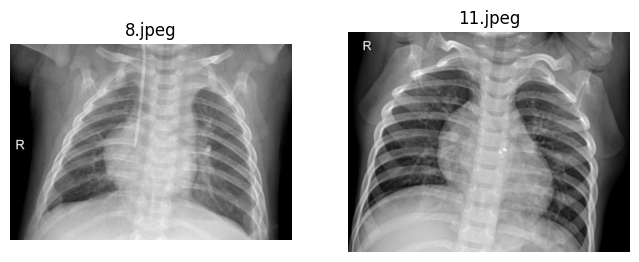

In [ ]:
normal_ids = test_predictions_df[test_predictions_df["predicted_label"] == "normal"]["id"].tolist()
print(normal_ids)

plt.figure(figsize=(8, 4))

for i, image_id in enumerate(normal_ids):
    img_path = TEST_DIR / image_id
    img = Image.open(img_path).convert("RGB")

    plt.subplot(1, len(normal_ids), i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(image_id)
    plt.axis("off")

plt.show()

In [ ]:
SAVE_DIR = Path("/content/gdrive/MyDrive/mth416")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

drive_output_path = SAVE_DIR / "q3_test_predictions_resnet18.csv"

test_predictions_df.to_csv(drive_output_path, index=False)

print("Saved complete prediction CSV to Google Drive:")
print(drive_output_path)

Saved complete prediction CSV to Google Drive:
/content/gdrive/MyDrive/mth416/q3_test_predictions_resnet18.csv


In [ ]:
report_predictions_df = test_predictions_df[["id", "predicted_label"]]

SAVE_DIR = Path("/content/gdrive/MyDrive/mth416")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

report_drive_path = SAVE_DIR / "q3_test_predictions_for_report.csv"

report_predictions_df.to_csv(report_drive_path, index=False)

print("Saved clean report prediction CSV to:")
print(report_drive_path)

display(report_predictions_df)

Saved clean report prediction CSV to:
/content/gdrive/MyDrive/mth416/q3_test_predictions_for_report.csv


,id,predicted_label
0,1.jpeg,abnormal
1,2.jpeg,abnormal
2,3.jpeg,abnormal
3,4.jpeg,abnormal
4,5.jpeg,abnormal
5,6.jpeg,abnormal
6,7.jpeg,abnormal
7,8.jpeg,normal
8,9.jpeg,abnormal
9,10.jpeg,abnormal
